# Ticket groups, families and survival

Four questions:

1. People on the same ticket are usually one family. Does the ticket add anything the family does not?
2. Is a passenger's survival tied to the survival of the others on their ticket, in their family, in their cabin, or on nearby ticket numbers, and does that help a model?
3. Do nearby ticket numbers show anything beyond class and port?
4. How strongly are class, fare, port and ticket tied together?

**Families** are `FamilyId` from `families_v3.ipynb`. **Same cabin** means sharing at least one cabin number (`C23 C25 C27` and `C25` count). **Nearby tickets** are different tickets whose numbers are 2 to 10 apart, prefix ignored. Survival is only known for the 891 train passengers, so every pair and group below is counted over train.

In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
warnings.filterwarnings("ignore")

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"], "font.size": 9.5,
    "text.color": INK, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.facecolor": SURFACE, "figure.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110,
})
def clean(ax, grid="x"):
    ax.grid(axis=grid, color=GRID, linewidth=0.6); ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)

def find_data():
    from pathlib import Path
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data" / "complete_data.csv").exists():
            return p / "data" / "complete_data.csv"
c = pd.read_csv(find_data())
t = c["Name"].str.extract(r",\s*([^.]+)\.")[0].str.strip().replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
c["Title"] = t.where(t.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
c["OwnDeck"] = c["Cabin"].str[0].fillna("None").replace({"T": "A", "G": "F"})
c["LogFare"] = np.log1p(c["Fare"]); c["AgeMissing"] = c["Age"].isna().astype(int)
c["PclassS"] = c["Pclass"].astype(str); c["Embarked"] = c["Embarked"].fillna("S")
c["Num"] = pd.to_numeric(c["Ticket"].str.extract(r"(\d+)$")[0])

tr = c[c["Dataset"] == "train"].reset_index(drop=True)
y = tr["Survived"].astype(int).values; n = len(tr)
fam, tik, num = tr["FamilyId"].values, tr["Ticket"].values, tr["Num"].values
tok = [set(x.split()) if isinstance(x, str) else set() for x in tr["Cabin"]]
P, E, S = tr["Pclass"].values, tr["Embarked"].values, tr["Sex"].values

I, J = np.triu_indices(n, 1)
sameT = tik[I] == tik[J]
sameF = (fam[I] == fam[J]) & ~pd.isna(fam[I])
sameC = np.array([bool(tok[i] & tok[j]) for i, j in zip(I, J)])
dist = np.abs(num[I] - num[J])
near = ~sameT & (dist >= 2) & (dist <= 10)

def pair_corr(m):
    a, b = y[I[m]], y[J[m]]
    return np.corrcoef(np.r_[a, b], np.r_[b, a])[0, 1]

## Findings

- **Ticket and family are mostly the same groups.** 73% of same-ticket pairs are family, and once family survival is in the model the ticket adds nothing further (+1.0 points for family, +0.9 for ticket or family).
- **Group survival helps a little, but not detectably.** Family, ticket, cabin and nearby-ticket survival rates each add 0.3 to 1.0 points of accuracy, none significant (p from 0.26 to 0.43). Ticket or family plus nearby tickets together add 1.6 points (p = 0.07): the best candidate, still borderline.
- **Nearby ticket numbers are class and port.** Non-family tickets 2 to 10 apart share a class 99% of the time and a port 89%. Matched on class, port and sex, their survival correlates only 0.02 more than tickets far apart.
- **Class, fare, ticket band and cabin recorded largely carry the same information** (Cramér's V 0.62 to 0.85 between class and the others). Port is only moderately tied to them (0.28 to 0.51).

## 1. Same ticket versus same family

Pairs of train passengers, by whether they share a ticket, a family, or both.

In [2]:
alone = (tr["SibSp"] + tr["Parch"] == 0).values
has_mate = pd.Series(tik).map(pd.Series(tik).value_counts()).gt(1).values
t1 = pd.DataFrame({
    "Pairs": [int((sameT & sameF).sum()), int((sameT & ~sameF).sum()), int((sameF & ~sameT).sum())],
}, index=["Same ticket and same family", "Same ticket, not family", "Same family, different ticket"])
t1.index.name = "Pair of train passengers"
display(t1)
display(Markdown(
    f"{(sameT & sameF).sum() / sameT.sum():.0%} of pairs on the same ticket are family. "
    f"{int(has_mate.sum())} train passengers share a ticket with another train passenger; "
    f"{int((has_mate & alone).sum())} of them travel with no family (SibSp and Parch both 0): servants, friends and companions."
))

,Pairs
Pair of train passengers,
Same ticket and same family,255
"Same ticket, not family",96
"Same family, different ticket",31


73% of pairs on the same ticket are family. 344 train passengers share a ticket with another train passenger; 75 of them travel with no family (SibSp and Parch both 0): servants, friends and companions.

Most ticket groups are families, but not all: 96 same-ticket pairs are not family, and 75 train passengers share a ticket while travelling with no family. That is the only thing the ticket can add over family.

## 2. Do group members share survival?

For each kind of group, the correlation between the survival of two members (1 = always the same fate, 0 = unrelated). For comparison, the bottom bars are pairs who share nothing but class, port and sex, on tickets more than 1,000 apart: they also correlate, because class, port and sex drive survival.

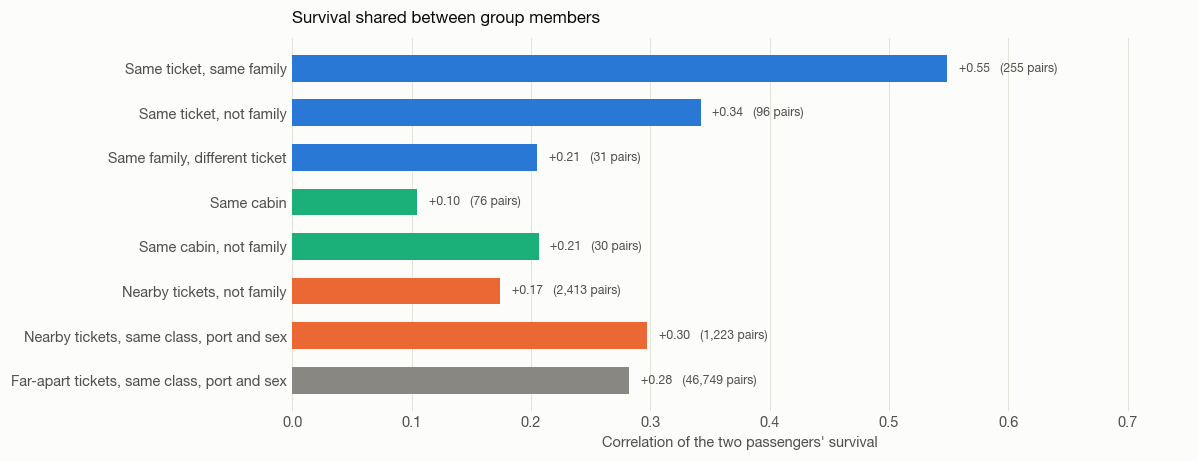

In [3]:
same_cps = (P[I] == P[J]) & (E[I] == E[J]) & (S[I] == S[J])
far = ~sameT & ~sameF & (dist > 1000)
ROWS = [
    ("Same ticket, same family", sameT & sameF, BLUE),
    ("Same ticket, not family", sameT & ~sameF, BLUE),
    ("Same family, different ticket", sameF & ~sameT, BLUE),
    ("Same cabin", sameC, AQUA),
    ("Same cabin, not family", sameC & ~sameF, AQUA),
    ("Nearby tickets, not family", near & ~sameF, ORANGE),
    ("Nearby tickets, same class, port and sex", near & ~sameF & same_cps, ORANGE),
    ("Far-apart tickets, same class, port and sex", far & same_cps, MUTED),
]
vals = [(lab, pair_corr(m), int(m.sum()), col) for lab, m, col in ROWS]
fig, ax = plt.subplots(figsize=(10.5, 4.4))
for i, (lab, r, k, col) in enumerate(vals):
    ax.barh(i, r, height=0.6, color=col, zorder=3)
    ax.text(r + 0.01, i, f"{r:+.2f}   ({k:,} pairs)", va="center", fontsize=8, color=INK2)
ax.set_yticks(range(len(vals)), [v[0] for v in vals]); ax.invert_yaxis()
ax.set_xlim(0, 0.75); ax.set_xlabel("Correlation of the two passengers' survival")
clean(ax)
ax.set_title("Survival shared between group members", loc="left", fontsize=11, pad=10)
plt.show()

Members of the same ticket and family share survival most strongly (0.55), and non-family ticket-mates still share it (0.34). Cabin-mates share less. The bottom two bars are the key comparison: strangers of the same class, port and sex correlate at 0.28 even on far-apart tickets, so most of the nearby-ticket correlation is class, port and sex, not the number.

### As a model feature

Each group becomes a feature: the survival rate of the passenger's other group members in train, with a flag for whether there are any. The base model is logistic regression on class, sex, title, age, SibSp, Parch, fare, port and deck from the passenger's own cabin, with no ticket information. The rates are worked out from the training folds only, so a passenger's own outcome, and the outcomes of held-out passengers, never leak in. 10-fold cross-validation repeated 10 times; p is corrected for the overlap between folds (Nadeau and Bengio).

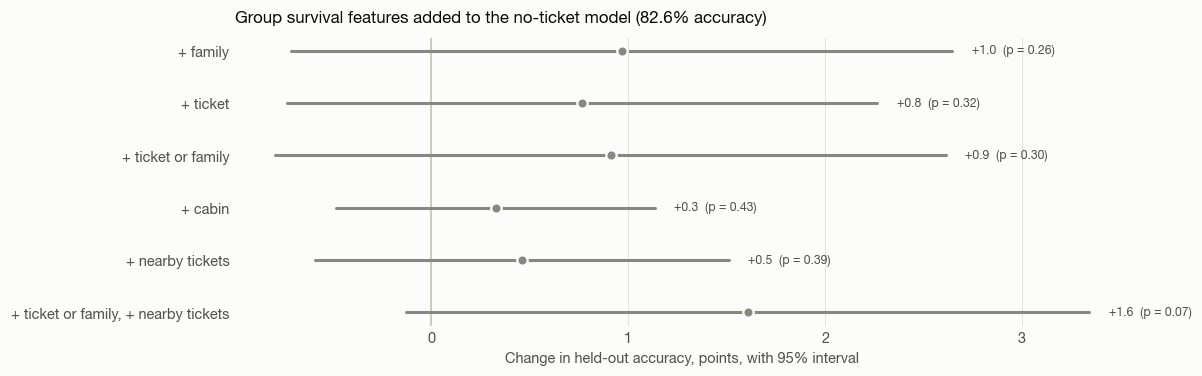

,Accuracy,Change (points),p,Train passengers with another member in train
Model,,,,
No group feature,82.6%,,,
+ family,83.6%,+1.0,0.26,32%
+ ticket,83.4%,+0.8,0.32,39%
+ ticket or family,83.6%,+0.9,0.30,42%
+ cabin,83.0%,+0.3,0.43,12%
+ nearby tickets,83.1%,+0.5,0.39,68%
"+ ticket or family, + nearby tickets",84.3%,+1.6,0.07,


Grey: the interval crosses 0, so no gain is detectable. Blue: a gain that clears it.

In [4]:
CAT = ["PclassS", "Sex", "Title", "Embarked", "OwnDeck"]
NUM = ["Age", "AgeMissing", "SibSp", "Parch", "LogFare"]
G = {
    "family": [np.where(fam == fam[i])[0] if not pd.isna(fam[i]) else np.array([], int) for i in range(n)],
    "ticket": [np.where(tik == tik[i])[0] for i in range(n)],
    "cabin": [np.array([j for j in range(n) if tok[i] & tok[j]], int) for i in range(n)],
    "nearby": [np.where((np.abs(num - num[i]) >= 2) & (np.abs(num - num[i]) <= 10) & (tik != tik[i]))[0]
               if not np.isnan(num[i]) else np.array([], int) for i in range(n)],
}
G = {k: [g[g != i] for i, g in enumerate(v)] for k, v in G.items()}
G["ticket or family"] = [np.union1d(a, b) for a, b in zip(G["family"], G["ticket"])]

def group_feats(names, train_idx):
    in_tr = np.zeros(n, bool); in_tr[train_idx] = True
    mu = y[train_idx].mean(); out = {}
    for g in names:
        r = np.zeros(n); h = np.zeros(n)
        for i in range(n):
            o = G[g][i][in_tr[G[g][i]]]
            if len(o):
                r[i] = y[o].mean() - mu; h[i] = 1
        out[g + "_rate"] = r; out[g + "_has"] = h
    return pd.DataFrame(out)

SETS = {"No group feature": [], "+ family": ["family"], "+ ticket": ["ticket"], "+ ticket or family": ["ticket or family"],
        "+ cabin": ["cabin"], "+ nearby tickets": ["nearby"], "+ ticket or family, + nearby tickets": ["ticket or family", "nearby"]}
splits = list(RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=0).split(tr, y))
acc = {}
for name, gs in SETS.items():
    a_ = []
    for a, b in splits:
        X = pd.concat([tr, group_feats(gs, a)], axis=1) if gs else tr
        extra = [col for col in X.columns if col.endswith("_rate") or col.endswith("_has")]
        pre = ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
                                 ("n", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM + extra)])
        m = make_pipeline(pre, LogisticRegression(max_iter=5000)).fit(X.iloc[a], y[a])
        a_.append(np.mean((m.predict_proba(X.iloc[b])[:, 1] >= 0.5) == y[b]))
    acc[name] = np.array(a_)
base = acc["No group feature"]; K = len(splits)
rows = []
for name, v in acc.items():
    d = v - base
    if name == "No group feature":
        rows.append(dict(Model=name, Accuracy=v.mean(), diff=np.nan, lo=np.nan, hi=np.nan, p=np.nan)); continue
    se = np.sqrt((1 / K + 1 / 9) * d.var(ddof=1))
    rows.append(dict(Model=name, Accuracy=v.mean(), diff=d.mean(), lo=d.mean() - 1.96 * se, hi=d.mean() + 1.96 * se,
                     p=2 * stats.t.sf(abs(d.mean() / se), K - 1)))
R = pd.DataFrame(rows).set_index("Model")
cover = {k: np.mean([len(g) > 0 for g in v]) for k, v in G.items()}

fig, ax = plt.subplots(figsize=(10.5, 3.4))
names = list(R.index[1:])
for i, nm in enumerate(names):
    r = R.loc[nm]
    col = BLUE if r["lo"] > 0 else MUTED
    ax.plot([100 * r["lo"], 100 * r["hi"]], [i, i], color=col, linewidth=2, solid_capstyle="round", zorder=3)
    ax.scatter([100 * r["diff"]], [i], s=46, color=col, edgecolor=SURFACE, linewidth=1.5, zorder=4)
    ax.text(100 * r["hi"] + 0.1, i, f"{100 * r['diff']:+.1f}  (p = {r['p']:.2f})", va="center", fontsize=8, color=INK2)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(range(len(names)), names); ax.invert_yaxis()
ax.set_xlabel("Change in held-out accuracy, points, with 95% interval")
clean(ax)
ax.set_title(f"Group survival features added to the no-ticket model ({100 * base.mean():.1f}% accuracy)", loc="left", fontsize=11, pad=10)
plt.show()
cov_txt = {"+ family": "family", "+ ticket": "ticket", "+ ticket or family": "ticket or family", "+ cabin": "cabin", "+ nearby tickets": "nearby"}
T = pd.DataFrame({
    "Accuracy": (100 * R["Accuracy"]).map("{:.1f}%".format),
    "Change (points)": [""] + [f"{100 * v:+.1f}" for v in R["diff"][1:]],
    "p": [""] + [f"{v:.2f}" for v in R["p"][1:]],
    "Train passengers with another member in train": [""] + [f"{cover[cov_txt[k]]:.0%}" if k in cov_txt else "" for k in R.index[1:]],
}, index=R.index)
display(T)
display(Markdown("Grey: the interval crosses 0, so no gain is detectable. Blue: a gain that clears it."))

Every interval crosses 0. Family is the single most useful group feature (+1.0 points), and ticket adds nothing on top of it. Cabin is limited by coverage: only 12% of train passengers have a cabin-mate in train. Nearby tickets cover 68% of passengers but carry little beyond class and port. The combination of ticket or family with nearby tickets (+1.6, p = 0.07) is worth re-testing in the final model, not banking on.

## 3. Do nearby tickets show anything beyond class and port?

Non-family pairs on different tickets 2 to 10 numbers apart, against random pairs of train passengers: how often they share class, port and sex.

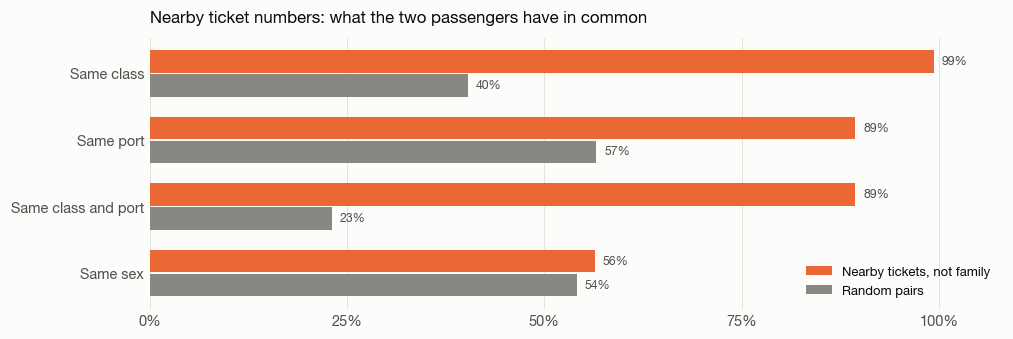

Matching on class, port and sex, survival correlates at +0.30 for nearby tickets and +0.28 for tickets more than 1,000 apart: the ticket number adds +0.02 beyond what class, port and sex already share.

In [5]:
rng = np.random.default_rng(0)
rnd = np.zeros(len(I), bool); rnd[rng.choice(len(I), 20000, replace=False)] = True
nf = near & ~sameF
labels_ = ["Same class", "Same port", "Same class and port", "Same sex"]
def share(m):
    return [np.mean(P[I[m]] == P[J[m]]), np.mean(E[I[m]] == E[J[m]]),
            np.mean((P[I[m]] == P[J[m]]) & (E[I[m]] == E[J[m]])), np.mean(S[I[m]] == S[J[m]])]
a_, b_ = share(nf), share(rnd)
fig, ax = plt.subplots(figsize=(10, 3.2))
yy = np.arange(len(labels_))
ax.barh(yy - 0.18, a_, height=0.34, color=ORANGE, label="Nearby tickets, not family", zorder=3)
ax.barh(yy + 0.18, b_, height=0.34, color=MUTED, label="Random pairs", zorder=3)
for i in range(len(labels_)):
    ax.text(a_[i] + 0.01, i - 0.18, f"{a_[i]:.0%}", va="center", fontsize=8, color=INK2)
    ax.text(b_[i] + 0.01, i + 0.18, f"{b_[i]:.0%}", va="center", fontsize=8, color=INK2)
ax.set_yticks(yy, labels_); ax.invert_yaxis()
ax.set_xlim(0, 1.08); ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
clean(ax)
ax.legend(loc="lower right", frameon=False, fontsize=8.5)
ax.set_title("Nearby ticket numbers: what the two passengers have in common", loc="left", fontsize=11, pad=10)
plt.show()
r_near = pair_corr(near & ~sameF & same_cps); r_far = pair_corr(far & same_cps)
display(Markdown(
    f"Matching on class, port and sex, survival correlates at {r_near:+.2f} for nearby tickets and {r_far:+.2f} for tickets "
    f"more than 1,000 apart: the ticket number adds {r_near - r_far:+.2f} beyond what class, port and sex already share."
))

Nearby ticket numbers are almost always the same class (99% against 40% for random pairs) and usually the same port (89% against 57%). They are no more likely to share a sex (56% against 54%), so they are not mainly couples or families.

## 4. How tied together are class, fare, port and ticket?

Cramér's V for each pair of features, across train and test (0 = unrelated, 1 = one fully determines the other). Fare is split into five equal-sized bands. Ticket band is the length of the ticket number and its first digit, prefix ignored.

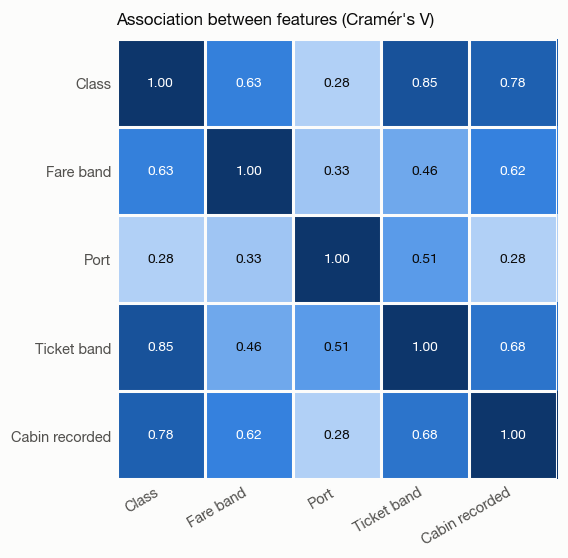

Rank correlation between class and fare: -0.71 (1st class is coded 1, so higher fares go with lower class numbers).

In [6]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b); chi = stats.chi2_contingency(ct)[0]
    return np.sqrt(chi / ct.values.sum() / (min(ct.shape) - 1))
s = c["Num"].map(lambda v: "" if pd.isna(v) else str(int(v)))
c["Ticket band"] = s.str[:1] + s.str.len().astype(str)
c["Fare band"] = pd.qcut(c["Fare"].rank(method="first"), 5, labels=False)
c["Cabin recorded"] = c["Cabin"].notna()
c["Class"] = c["Pclass"]; c["Port"] = c["Embarked"]
cols = ["Class", "Fare band", "Port", "Ticket band", "Cabin recorded"]
M = pd.DataFrame([[1.0 if a == b else cramers_v(c[a], c[b]) for b in cols] for a in cols], index=cols, columns=cols)
from matplotlib.colors import LinearSegmentedColormap
SEQ = LinearSegmentedColormap.from_list("seq", ["#f3f2ee", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
fig, ax = plt.subplots(figsize=(6.6, 5.2))
ax.imshow(M.values, cmap=SEQ, vmin=0, vmax=1)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = M.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if v >= 0.55 else INK)
ax.set_xticks(range(len(cols)), cols, rotation=30, ha="right"); ax.set_yticks(range(len(cols)), cols)
for x in np.arange(-.5, len(cols)):
    ax.axvline(x, color=SURFACE, linewidth=2); ax.axhline(x, color=SURFACE, linewidth=2)
ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_title("Association between features (Cramér's V)", loc="left", fontsize=11, pad=10)
plt.show()
display(Markdown(f"Rank correlation between class and fare: {stats.spearmanr(c['Pclass'], c['Fare'], nan_policy='omit')[0]:.2f} (1st class is coded 1, so higher fares go with lower class numbers)."))

Class is tied most strongly to ticket band (0.85) and to whether a cabin is recorded (0.78), then to fare (0.63). Port is the most independent of the five, linked mainly through the ticket band (0.51), because some number ranges were sold at one port (26xx at Cherbourg, 330xxx and 367xxx at Queenstown). For a linear model, this means class, fare, ticket band and cabin recorded overlap heavily: adding all of them mostly splits the same effect between columns.